In [2]:
import import_ipynb
from xraymodel import load_dataset

found 1695 images
{3: 3, 15: 1, 16: 0}
{3: 3, 1: 15, 0: 16}


In [8]:
%run ./xraymodel.ipynb

found 1695 images
{3: 3, 15: 1, 16: 0}
{3: 3, 1: 15, 0: 16}


In [9]:
idx = 42
pathology = "Pneumothorax"

dataset_idx = DATASET_LABEL_INDICES[pathology]
model_idx = DATASET_TO_MODEL_INDICES[dataset_idx]

ground_truth = NIH_GOOGLE_LABELS_LIST[idx, dataset_idx]
prediction = MODEL_SCORE_PREDICTIONS[idx, model_idx]

print(ground_truth, prediction)

0.0 0.4189091


In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

In [29]:
pathology = "Pneumothorax"
idx = DATASET_LABEL_INDICES[pathology]

# Load dataset
dataset = load_dataset()
images = np.stack([x["img"] for x in dataset])

# Ground truth and predictions
gt = NIH_GOOGLE_LABELS_LIST[:, idx]
scores = MODEL_SCORE_PREDICTIONS_CONVERTED[:, idx]

# Classification results (threshold = 0.5)
fp_indices = np.where((gt == 0) & (scores >= 0.5))[0]
tp_indices = np.where((gt == 1) & (scores >= 0.5))[0]
fn_indices = np.where((gt == 1) & (scores < 0.5))[0]
tn_indices = np.where((gt == 0) & (scores < 0.5))[0]

found 1695 images


In [30]:
# Select a false positive as query
query_idx = fp_indices[0]

# Flatten images for pixel-based comparison
X = images.reshape(len(images), -1).astype(np.float32)

# Find 10 nearest neighbors (excluding query image)
nn = NearestNeighbors(n_neighbors=11, metric="euclidean")
nn.fit(X)

distances, indices = nn.kneighbors(X[query_idx:query_idx + 1])

# Exclude query image
mask = indices[0] != query_idx
neighbor_indices = indices[0][mask][:10]
neighbor_distances = distances[0][mask][:10]

# Query + nearest neighbors
plot_indices = [query_idx] + list(neighbor_indices)

In [32]:
def get_classification(idx):
    if idx in fp_indices: return "FP"
    if idx in tp_indices: return "TP"
    if idx in fn_indices: return "FN"
    if idx in tn_indices: return "TN"
    return "Unknown"

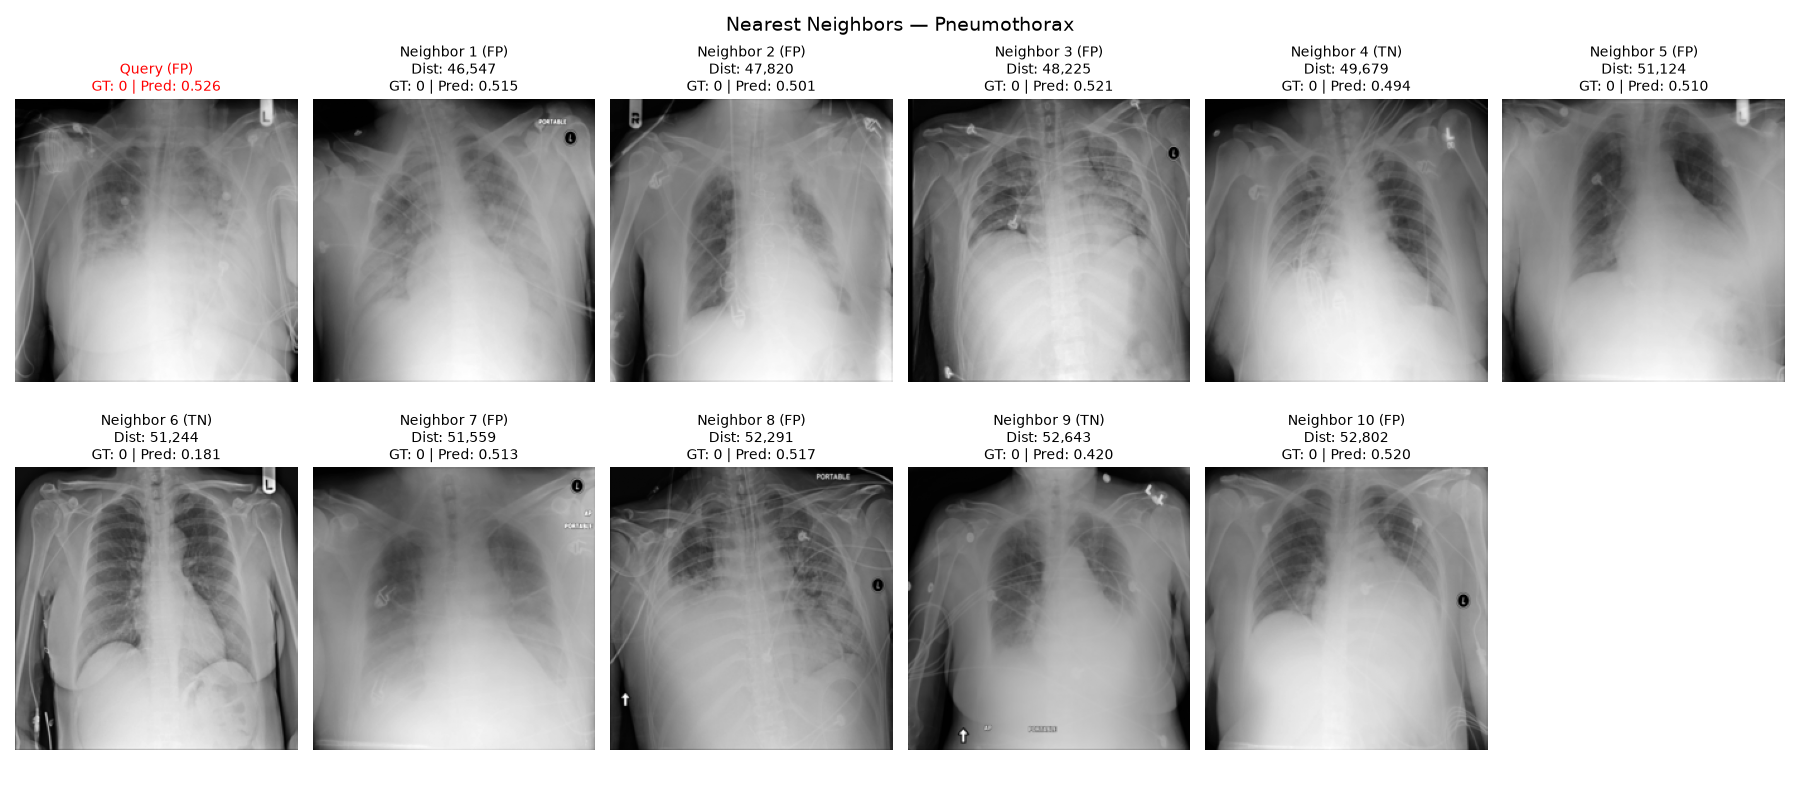

In [33]:
import matplotlib.pyplot as plt

# Exclude query image itself
neighbor_indices = indices[0][indices[0] != query_idx][:10]
neighbor_distances = distances[0][indices[0] != query_idx][:10]

# Query + 10 neighbors
plot_indices = [query_idx] + list(neighbor_indices)

def get_classification(idx):
    if idx in fp_indices: return "FP"
    if idx in tp_indices: return "TP"
    if idx in fn_indices: return "FN"
    if idx in tn_indices: return "TN"
    return "Unknown"

fig, axes = plt.subplots(2, 6, figsize=(18, 8))
axes = axes.flatten()

for i, img_idx in enumerate(plot_indices):
    axes[i].imshow(images[img_idx, 0], cmap="gray")
    axes[i].axis("off")

    ground_truth = gt[img_idx]
    prediction = scores[img_idx]
    classification = get_classification(img_idx)

    if i == 0:
        axes[i].set_title(
            f"Query ({classification})\n"
            f"GT: {ground_truth:.0f} | Pred: {prediction:.3f}",
            color="red",
            fontsize=10
        )
    else:
        axes[i].set_title(
            f"Neighbor {i} ({classification})\n"
            f"Dist: {neighbor_distances[i-1]:,.0f}\n"
            f"GT: {ground_truth:.0f} | Pred: {prediction:.3f}",
            fontsize=10
        )

# Hide unused subplot
for ax in axes[len(plot_indices):]:
    ax.axis("off")

plt.suptitle(f"Nearest Neighbors — {pathology}", fontsize=14)
plt.tight_layout(h_pad=3)
plt.show()